### Multiclass Classfication
: 결과가 여러개의 클래스로 나오는 경우
#### Wine Recognition Dataset
: 와인의 13가지 특징으로 3개의 품종 중 어디에 속하는지 다중분류
- 데이터 개수: 178개
- 입력 특징: 13개
- 정답 클래스: 3개(1, 2, 3 중 하나)

In [4]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
torch.manual_seed(42)

#### step 1. 데이터 불러오기

In [10]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine/wine.data"
cnm = [
    "class",
    "Alcohol",
    "Malicacid",
    "Ash",
    "Alcalinity_of_ash",
    "Magnesium",
    "Total_phenols",
    "Flavanoids",
    "Nonflavanoid_phenols",
    "Proanthocyanins",
    "Color_intensity",
    "Hue",
    "0D280_0D315_of_diluted_wines",
    "Proline",
]
df = pd.read_csv(url, names=cnm)
# 입력(x), 출력(y) 분리
x = cnm[1:]
X = torch.tensor(df[x].values, dtype=torch.float32)
# 원본 클래스 1, 2, 3 -> 0, 1, 2 변환
y = df["class"].values - 1
Y = torch.tensor(y, dtype=torch.float32)
# train(80), test(20)로 분할
tri = []
tei = []
for i in [0, 1, 2]:
    ci = np.where(Y == i)[0]
    ci = torch.randperm(len(ci)).numpy()
    sp = int(len(ci) * 0.8)
    tri.extend(ci[:sp].tolist())
    tei.extend(ci[sp:].tolist())
# 학습/테스트 인덱스 섞기
tri = torch.tensor(tri)[torch.randperm(len(tri))]
tei = torch.tensor(tei)[torch.randperm(len(tei))]
# 원본 데이터 2분리(train입력/출력, test입력/출력)
xtr = X[tri.numpy()]
xte = X[tei.numpy()]
ytr = Y[tri.numpy()]
yte = Y[tei.numpy()]

# 표준화
mean = xtr.mean(dim=0)
std = xtr.std(dim=0).clamp(min=1e-5)

xtrs = (xtr - mean) / std
xtes = (xte - mean) / std

ytr = torch.tensor(ytr, dtype=torch.long)
yte = torch.tensor(yte, dtype=torch.long)

print("X_train :", xtr.shape, xtr.dtype)
print("Y_train :", ytr.shape, ytr.dtype)
print("X_test :", xte.shape, xte.dtype)
print("Y_test :", yte.shape, yte.dtype)

X_train : torch.Size([141, 13]) torch.float32
Y_train : torch.Size([141]) torch.int64
X_test : torch.Size([37, 13]) torch.float32
Y_test : torch.Size([37]) torch.int64


C:\Users\lyb53\AppData\Local\Temp\ipykernel_28636\160030605.py:50: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  ytr = torch.tensor(ytr, dtype=torch.long)
C:\Users\lyb53\AppData\Local\Temp\ipykernel_28636\160030605.py:51: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  yte = torch.tensor(yte, dtype=torch.long)


#### step 2. DataLoder 생성

In [11]:
bs=16
trds=TensorDataset(xtr,ytr)
teds=TensorDataset(xte,yte)
trdl=DataLoader(trds,batch_size=bs,shuffle=True)
tedl=DataLoader(teds,batch_size=bs,shuffle=True)

#### step 3. 학습 모델

In [ ]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Sequential(nn.Linear(13, 30), nn.ReLU(), nn.Linear(30, 3))

    def forward(self, x):
        return self.linear(x)


m = MLP()

#### step 4. 모델 학습

In [ ]:
LR = 1e-3
EPOCH = 100
op = optim.Adam(m.parameters(), lr=LR)
cri = nn.CrossEntropyLoss()
lh = []
n = len(trdl.dataset)
save_path = "results/MLP_Wine.pt"
if os.path.exists(save_path):
    m.load_state_dict(torch.load(save_path))
    print("기존의 저장된 모델을 불러왔다")
else:
    m.train()
    for ep in range(EPOCH):
        rloss = 0
        for i, j in trdl:
            yh = m(i)
            loss = cri(yh, j)
            op.zero_grad()
            loss.backward()
            op.step()
            rloss += loss.item() * i.shape[0]
        eloss = rloss / n
        lh.append(eloss)
        if ep % 10 == 0:
            print(f"에포크: {ep+1}, train loss: {eloss:.4f}")
    os.makedirs("results", exist_ok=True)
    torch.save(m.state_dict(), save_path)

에포크: 1, train loss: 0.2579
에포크: 11, train loss: 0.1187
에포크: 21, train loss: 0.1472
에포크: 31, train loss: 0.3799
에포크: 41, train loss: 0.0914
에포크: 51, train loss: 0.0910
에포크: 61, train loss: 0.1087
에포크: 71, train loss: 0.1927
에포크: 81, train loss: 0.0853
에포크: 91, train loss: 0.0829


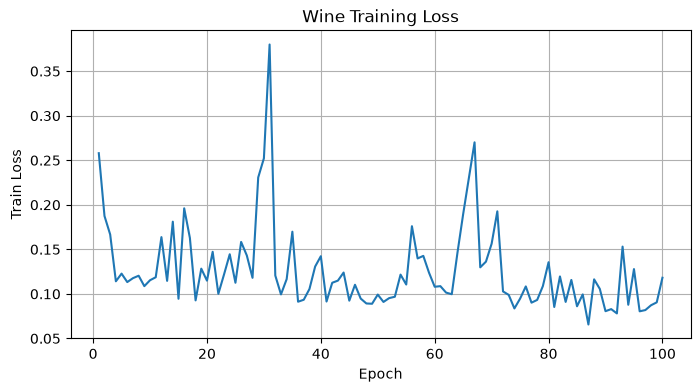

In [18]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCH + 1), lh)
plt.xlabel("Epoch")
plt.ylabel("Train Loss")
plt.title("Wine Training Loss")
plt.grid(True)

#### step 5. 모델 테스트

In [22]:
m.eval()
correct = 0
total = 0
# 테스트 데이터 전체의 예측값과 실제 정답을 저장하기 위해 리스트 생성
all_predictions = []
all_target = []
with torch.no_grad():
    for i, j in tedl:
        yh = m(i)
        pred = yh.argmax(dim=1)
        correct += (pred == j).sum().item()
        total += j.size(0)
        all_predictions.append(pred)
        all_target.append(j)
accuracy = correct / total * 100
y_pred = torch.cat(all_predictions)
y_true=torch.cat(all_target)
print(y_pred.shape)
print(f'test accuracy: {correct}/{total} ({accuracy:.1f}%)')

torch.Size([37])
test accuracy: 36/37 (97.3%)
